# Where does behavioural variability live? lab > mouse > session > trial > moment

The agnostic version of the individuality question: no LDA and no chosen projection. All 400 syllable features (40 bins × 8 paw states + whisking + licking, one-hot per trial) count, and each level of the hierarchy gets only the variance its own sampling noise cannot explain. Estimator and caveats are in the header of `nested_variance.py`.

| part | question |
|---|---|
| 1 | how much variance sits at each level: task time, lab, mouse, session, trial-wide, moment |
| 2 | is each level real? restricted-permutation nulls (Anderson 2001 logic) |
| 3 | how much data identifies a mouse? Spearman–Brown reliability from the components |
| 4 | where in the trial does each level live? components bin by bin |
| 5 | distances between trials and sessions by relatedness (the "staircase") |
| 6 | stability in time: distance vs trial lag within a session and day lag across sessions |

Same sessions and filters as `4_mice/lda_shrinkage.ipynb` (260 sessions, 56 mice), proficient only.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date

HERE = pathlib.Path.cwd().resolve()
while not (HERE / 'nested_variance.py').exists() and HERE != HERE.parent:
    HERE = HERE / 'nested_variance' if (HERE / 'nested_variance').exists() else HERE.parent
PI = HERE.parent
for p in (str(PI), str(HERE)):
    if p not in sys.path:
        sys.path.insert(0, p)
import importlib
import nested_variance as nv
importlib.reload(nv)
import paper_style as ps
ps.use('paper')
ps.use_paw_states('uniform')

FIGDIR = HERE / 'figures'
N_PERM_MOUSE = 200      # sessions moved between mice of one lab
N_PERM_LAB = 200        # mice moved between labs
N_PERM_SESSION = 50     # trials moved between sessions of one mouse (the slow one, ~3 s each)
N_PAIRS = 200_000       # per relatedness kind, part 5
SEED = 0
LEVEL_COLORS = {'Task time': '#C9B458', 'Lab': '#22344A', 'Mouse': '#3E8E54', 'Session': '#8FCB8B',
                'Trial-wide': '#9FB3C6', 'Moment': '#D9D9D9'}
fs_small = plt.rcParams['font.size'] * 0.8

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Data

In [2]:
codes, meta = nv.load_trials()
OH = nv.one_hot(ps.paw_codes(codes))                   # [trials x 40 bins x 10], display paw numbering
N, B, S = OH.shape
Y = OH.reshape(N, -1)
groups, K = nv.design(meta)
print(f'{N} trials x {Y.shape[1]} features; trials per session median {meta.groupby("session").size().median():.0f}, '
      f'sessions per mouse median {meta.groupby("mouse_name").session.nunique().median():.0f}')

159640 trials, 260 sessions, 56 mice; dropping 0.7% with a missing bin


kept 158564 trials, 260 sessions, 56 mice, 10 labs


158564 trials x 400 features; trials per session median 564, sessions per mouse median 4


## 1. Variance components

**Scale.** The variance of one syllable indicator at a random moment of a random trial, summed over the 10 syllables. It splits exactly into:
* **Task time**: how the population's mean use changes across the 40 bins.
* The within-bin variance, split by the nested estimator into **lab**, **mouse**, **session** and **trial**.
* The trial level, split further into **trial-wide** (shared by all bins of an epoch) and **moment** (bin to bin).

Components are unbiased and are not truncated at zero. The **z-scored** column weights every feature equally; it is the mean, over features, of each feature's share of its own within-bin variance.

In [3]:
COMP = nv.components(Y, groups, K)                      # [lab, mouse, session, trial] x 400 features
mu = Y.mean(axis=0).reshape(B, S)
task_time = ((mu - mu.mean(axis=0)) ** 2).mean(axis=0).sum()
within = COMP.sum(axis=1) / B                            # per-moment scale
total = Y.reshape(N, B, S).reshape(-1, S).var(axis=0).sum()
# Not equal by construction: the components estimate the POPULATION variance, while the pooled sample variance
# of 10 unequal labs under-counts lab-to-lab variance (by about 1 - sum n_lab^2 / N^2 of it). Shares use the components.
print(f'total: components {task_time + within.sum():.4f} vs pooled sample variance {total:.4f}')

# trial level -> trial-wide + moment, on within-session residuals
sess = groups[2]
A, _ = nv._indicator(sess, N)
sess_mean = np.asarray(A @ Y) / np.bincount(sess)[:, None]
R = (Y - sess_mean[sess]).reshape(N, B, S)
TW, MO = nv.trial_wide_split(R)
trial_wide, moment = TW.sum() * 10 / B, MO.sum() * 10 / B
print(f'trial level: nested estimator {within[3]:.4f} vs trial-wide + moment {trial_wide + moment:.4f}')
scale = within[3] / (trial_wide + moment)                # reconcile the two estimators' df conventions
trial_wide, moment = trial_wide * scale, moment * scale

PARTS = pd.Series({'Task time': task_time, 'Lab': within[0], 'Mouse': within[1], 'Session': within[2],
                   'Trial-wide': trial_wide, 'Moment': moment})
feat_var = COMP.sum(axis=0)
ok = feat_var > 1e-6
Z = pd.Series((COMP[:, ok] / feat_var[ok]).mean(axis=1), index=['Lab', 'Mouse', 'Session', 'Trial'])

Rf = R.reshape(N, -1)
COND = {name: nv.condition_component(Rf, meta[col].astype(str).to_numpy()).sum() / B
        for name, col in [('outcome', 'outcome'), ('contrast', 'contrast'), ('block', 'block'),
                          ('side', 'side'), ('all task conditions', 'trial_type')]}

tab = pd.DataFrame({'variance': PARTS, 'share of total': PARTS / PARTS.sum(),
                    'share of within-bin': PARTS.drop('Task time') / PARTS.drop('Task time').sum()})
print(tab.round(3).to_string())
print('\nz-scored features (mean per-feature share):', Z.round(3).to_dict())
mouse_lab = PARTS[['Lab', 'Mouse']].sum()
between = PARTS[['Lab', 'Mouse', 'Session']].sum()
print(f'\nof the variance ABOVE the trial (lab + mouse + session): lab {PARTS.Lab / between:.2f}, '
      f'mouse {PARTS.Mouse / between:.2f}, session {PARTS.Session / between:.2f}')
print('task conditions, inside the trial level (share of total):',
      {k: round(v / PARTS.sum(), 4) for k, v in COND.items()})
print(f'mouse vs all task conditions: {PARTS.Mouse / COND["all task conditions"]:.1f}x')

total: components 1.1726 vs pooled sample variance 1.1581


trial level: nested estimator 0.8955 vs trial-wide + moment 0.8941


            variance  share of total  share of within-bin
Lab            0.013           0.011                0.013
Moment         0.462           0.394                0.468
Mouse          0.047           0.040                0.048
Session        0.032           0.028                0.033
Task time      0.184           0.157                  NaN
Trial-wide     0.433           0.370                0.438

z-scored features (mean per-feature share): {'Lab': 0.008, 'Mouse': 0.032, 'Session': 0.024, 'Trial': 0.936}

of the variance ABOVE the trial (lab + mouse + session): lab 0.14, mouse 0.51, session 0.35
task conditions, inside the trial level (share of total): {'outcome': 0.016, 'contrast': 0.0067, 'block': 0.0019, 'side': 0.002, 'all task conditions': 0.0236}
mouse vs all task conditions: 1.7x


## 2. Is each level real?

Restricted permutations keep everything below the tested level intact and move whole units within the level above:
* **Session**: trials shuffled between the sessions of one mouse.
* **Mouse**: sessions shuffled between the mice of one lab.
* **Lab**: mice shuffled between labs.

The statistic is the trace component, summed over features.

In [4]:
rng = np.random.default_rng(SEED)
obs = COMP.sum(axis=1)


def null_component(level, n_perm):
    out = []
    for _ in range(n_perm):
        m = meta.copy()
        if level == 'session':
            m['session'] = m.groupby('mouse_name')['session'].transform(lambda s: rng.permutation(s.to_numpy()))
        elif level == 'mouse':
            new = nv.permute_within(m['session'], m['lab'], rng)                      # session -> another session's slot
            owner = m.drop_duplicates('session').set_index('session')['mouse_name']
            m['mouse_name'] = m['session'].map(new).map(owner)
        else:
            mice = m.drop_duplicates('mouse_name').set_index('mouse_name')['lab']
            m['lab'] = m['mouse_name'].map(pd.Series(rng.permutation(mice.to_numpy()), index=mice.index))
        g, K_ = nv.design(m)
        out.append(nv.components(Y, g, K_).sum(axis=1)[['lab', 'mouse', 'session'].index(level)])
    return np.array(out)


NULL = {'session': null_component('session', N_PERM_SESSION),
        'mouse': null_component('mouse', N_PERM_MOUSE),
        'lab': null_component('lab', N_PERM_LAB)}
for i, lvl in enumerate(['lab', 'mouse', 'session']):
    nl = NULL[lvl]
    p = (1 + (nl >= obs[i]).sum()) / (1 + len(nl))
    print(f'{lvl:8s} observed {obs[i]:8.2f}   null 95th pct {np.percentile(nl, 95):8.2f}   '
          f'(null mean {nl.mean():+.2f})   p = {p:.3f}  ({len(nl)} permutations)')

lab      observed     0.52   null 95th pct     0.18   (null mean +0.01)   p = 0.005  (200 permutations)
mouse    observed     1.89   null 95th pct     0.10   (null mean -0.01)   p = 0.005  (200 permutations)
session  observed     1.30   null 95th pct     0.00   (null mean +0.00)   p = 0.020  (50 permutations)


## 3. How much data identifies a mouse?

Spearman–Brown from the trace components. Reliability of a mouse's mean syllable profile, from $n_s$ sessions of $n_t$ trials each:
$$R = \frac{\sigma^2_{\text{mouse}}}{\sigma^2_{\text{mouse}} + \sigma^2_{\text{session}}/n_s + \sigma^2_{\text{trial}}/(n_t n_s)}$$
"Within lab" uses the mouse component only. "Across labs" adds the lab component to the numerator, which is the reliability of a mouse among all mice.

In [5]:
v = dict(zip(['lab', 'mouse', 'session', 'trial'], obs))
NT = np.unique(np.round(np.logspace(0, np.log10(1500), 60)).astype(int))
def reliability(nt, ns, with_lab=False):
    sig = v['mouse'] + (v['lab'] if with_lab else 0)
    return sig / (sig + v['session'] / ns + v['trial'] / (nt * ns))
med_nt = int(meta.groupby('session').size().median())
for ns in (1, 3, 10):
    nt80 = NT[np.argmax(reliability(NT, ns) >= 0.8)] if (reliability(NT, ns) >= 0.8).any() else None
    print(f'{ns:2d} session(s): R(within lab) at the median {med_nt} trials = {reliability(med_nt, ns):.2f}, '
          f'across labs {reliability(med_nt, ns, True):.2f}; 0.8 within lab reached at '
          f'{nt80 if nt80 else "> 1500"} trials/session; ceiling (infinite trials) {reliability(1e9, ns):.2f}')
print(f'single trial: R(within lab) = {reliability(1, 1):.3f}')

 1 session(s): R(within lab) at the median 564 trials = 0.58, across labs 0.64; 0.8 within lab reached at > 1500 trials/session; ceiling (infinite trials) 0.59
 3 session(s): R(within lab) at the median 564 trials = 0.81, across labs 0.84; 0.8 within lab reached at 339 trials/session; ceiling (infinite trials) 0.81
10 session(s): R(within lab) at the median 564 trials = 0.93, across labs 0.95; 0.8 within lab reached at 11 trials/session; ceiling (infinite trials) 0.94
single trial: R(within lab) = 0.048


## 4. Where in the trial does each level live?

In [6]:
COMP_BIN = COMP.reshape(4, B, S)
SHARE_BIN = COMP_BIN.sum(axis=2) / COMP_BIN.sum(axis=(0, 2))      # [levels x bins], share of within-bin variance
CH = {'Paw': slice(0, nv.N_PAW_STATES), 'Whisk': slice(8, 9), 'Lick': slice(9, 10)}
SHARE_CH = {ch: COMP_BIN[:, :, sl].sum(axis=2) / COMP_BIN[:, :, sl].sum(axis=(0, 2)) for ch, sl in CH.items()}
ep = np.repeat(ps.EPOCH_SHORT, B // 4)
print(pd.DataFrame(SHARE_BIN.T, columns=['lab', 'mouse', 'session', 'trial']).groupby(ep, sort=False).mean().round(3))
for ch, sh in SHARE_CH.items():
    print(f'{ch:6s} mouse share by epoch:', pd.Series(sh[1]).groupby(ep, sort=False).mean().round(3).to_dict())

           lab  mouse  session  trial
Pre-Q    0.018  0.036    0.026  0.920
Quiesc.  0.006  0.051    0.029  0.915
Choice   0.005  0.057    0.035  0.902
ITI      0.021  0.048    0.040  0.891
Paw    mouse share by epoch: {'Pre-Q': 0.023, 'Quiesc.': 0.021, 'Choice': 0.047, 'ITI': 0.04}
Whisk  mouse share by epoch: {'Pre-Q': 0.069, 'Quiesc.': 0.131, 'Choice': 0.082, 'ITI': 0.033}
Lick   mouse share by epoch: {'Pre-Q': 0.033, 'Quiesc.': 0.046, 'Choice': 0.053, 'ITI': 0.071}


## 5. Distances by relatedness

* **Trials**: Hamming distance, the fraction of the 40 bins whose syllable differs.
* **Sessions**: Euclidean distance between session-mean occupancy profiles. Every session averages a similar number of trials, so the noise floor is shared across kinds.

If the mouse is an organising level, the big step falls between "same mouse" and "same lab".

In [7]:
rng = np.random.default_rng(SEED + 1)
KINDS = ['same session', 'same mouse', 'same lab', 'other lab']
DIST_T = {}
for k in KINDS:
    i, j = nv.sample_pairs(meta, k, N_PAIRS, rng)
    DIST_T[k] = nv.hamming_pairs(codes, i, j)
# adjacent trials, as the finest within-session scale
nxt = np.where((meta['session'].to_numpy()[1:] == meta['session'].to_numpy()[:-1]))[0]
DIST_T = {'adjacent trial': nv.hamming_pairs(codes, nxt, nxt + 1), **DIST_T}

ses = meta.drop_duplicates('session').reset_index(drop=True)
SP = sess_mean                                                           # [sessions x 400], factorize order
s_order = pd.factorize(meta['session'], sort=True)[1]
ses = ses.set_index('session').loc[s_order].reset_index()
D = np.sqrt(((SP[:, None] - SP[None]) ** 2).sum(-1))
iu = np.triu_indices(len(SP), 1)
same_m = (ses.mouse_name.to_numpy()[:, None] == ses.mouse_name.to_numpy()[None])[iu]
same_l = (ses.lab.to_numpy()[:, None] == ses.lab.to_numpy()[None])[iu]
DIST_S = {'same mouse': D[iu][same_m], 'same lab': D[iu][same_l & ~same_m], 'other lab': D[iu][~same_l]}
for name, d in (('trials', DIST_T), ('sessions', DIST_S)):
    print(name + ':  ' + '   '.join(f'{k} {np.mean(x):.3f}' for k, x in d.items()))
st = {k: np.mean(x) for k, x in DIST_S.items()}
print(f"session steps: same mouse -> same lab +{st['same lab'] - st['same mouse']:.3f}, "
      f"same lab -> other lab +{st['other lab'] - st['same lab']:.3f}")

trials:  adjacent trial 0.726   same session 0.780   same mouse 0.800   same lab 0.833   other lab 0.836
sessions:  same mouse 1.524   same lab 2.450   other lab 2.685
session steps: same mouse -> same lab +0.926, same lab -> other lab +0.234


## 6. Stability in time

* **Within a session**: Hamming distance between two trials against their trial lag.
* **Across sessions of one mouse**: session-profile distance against the days between the sessions, with the same-lab and other-lab levels of part 5 as references.

Drift would make the same-mouse curve rise toward the other-mouse level. A trait would keep it flat and below.

In [8]:
rng = np.random.default_rng(SEED + 2)
LAGS = np.array([1, 2, 3, 5, 8, 13, 20, 35, 60, 100, 170, 300, 500])
starts = meta.groupby('session').cumcount().to_numpy()
sizes = meta.groupby('session')['trial'].transform('size').to_numpy()
LAG_D = []
for lag in LAGS:
    ok = np.where(starts + lag < sizes)[0]
    pick = rng.choice(ok, min(len(ok), 50_000), replace=False)
    LAG_D.append(nv.hamming_pairs(codes, pick, pick + lag).mean())
LAG_D = np.array(LAG_D)
print('Hamming vs trial lag:', dict(zip(LAGS, LAG_D.round(3))))

dates = ses['date'].to_numpy()
dd = np.abs((dates[:, None] - dates[None]).astype('timedelta64[D]').astype(float))[iu]
DAY = pd.DataFrame({'days': dd[same_m], 'dist': D[iu][same_m]}).dropna()
DAY_BINS = [0, 1, 2, 4, 8, 16, 32, 64, 400]
DAY['bin'] = pd.cut(DAY['days'], DAY_BINS, right=True)
DAY_SUM = DAY.groupby('bin', observed=True)['dist'].agg(['mean', 'sem', 'size'])
print(DAY_SUM.round(3))
rho = pd.Series(DAY['days']).corr(DAY['dist'], method='spearman')
print(f'same-mouse session distance vs days apart: Spearman rho = {rho:+.2f} (n = {len(DAY)} pairs, '
      f'pairs not independent)')

Hamming vs trial lag: {1: 0.725, 2: 0.734, 3: 0.739, 5: 0.741, 8: 0.746, 13: 0.752, 20: 0.755, 35: 0.76, 60: 0.763, 100: 0.764, 170: 0.775, 300: 0.789, 500: 0.795}
            mean    sem  size
bin                          
(0, 1]     1.407  0.048   152
(1, 2]     1.496  0.054   116
(2, 4]     1.519  0.042   136
(4, 8]     1.719  0.065    95
(8, 16]    1.849  0.127    30
(16, 32]   1.378  0.047    71
(32, 64]   1.695  0.208     2
(64, 400]  2.348  0.092     2
same-mouse session distance vs days apart: Spearman rho = +0.14 (n = 609 pairs, pairs not independent)


## The figure

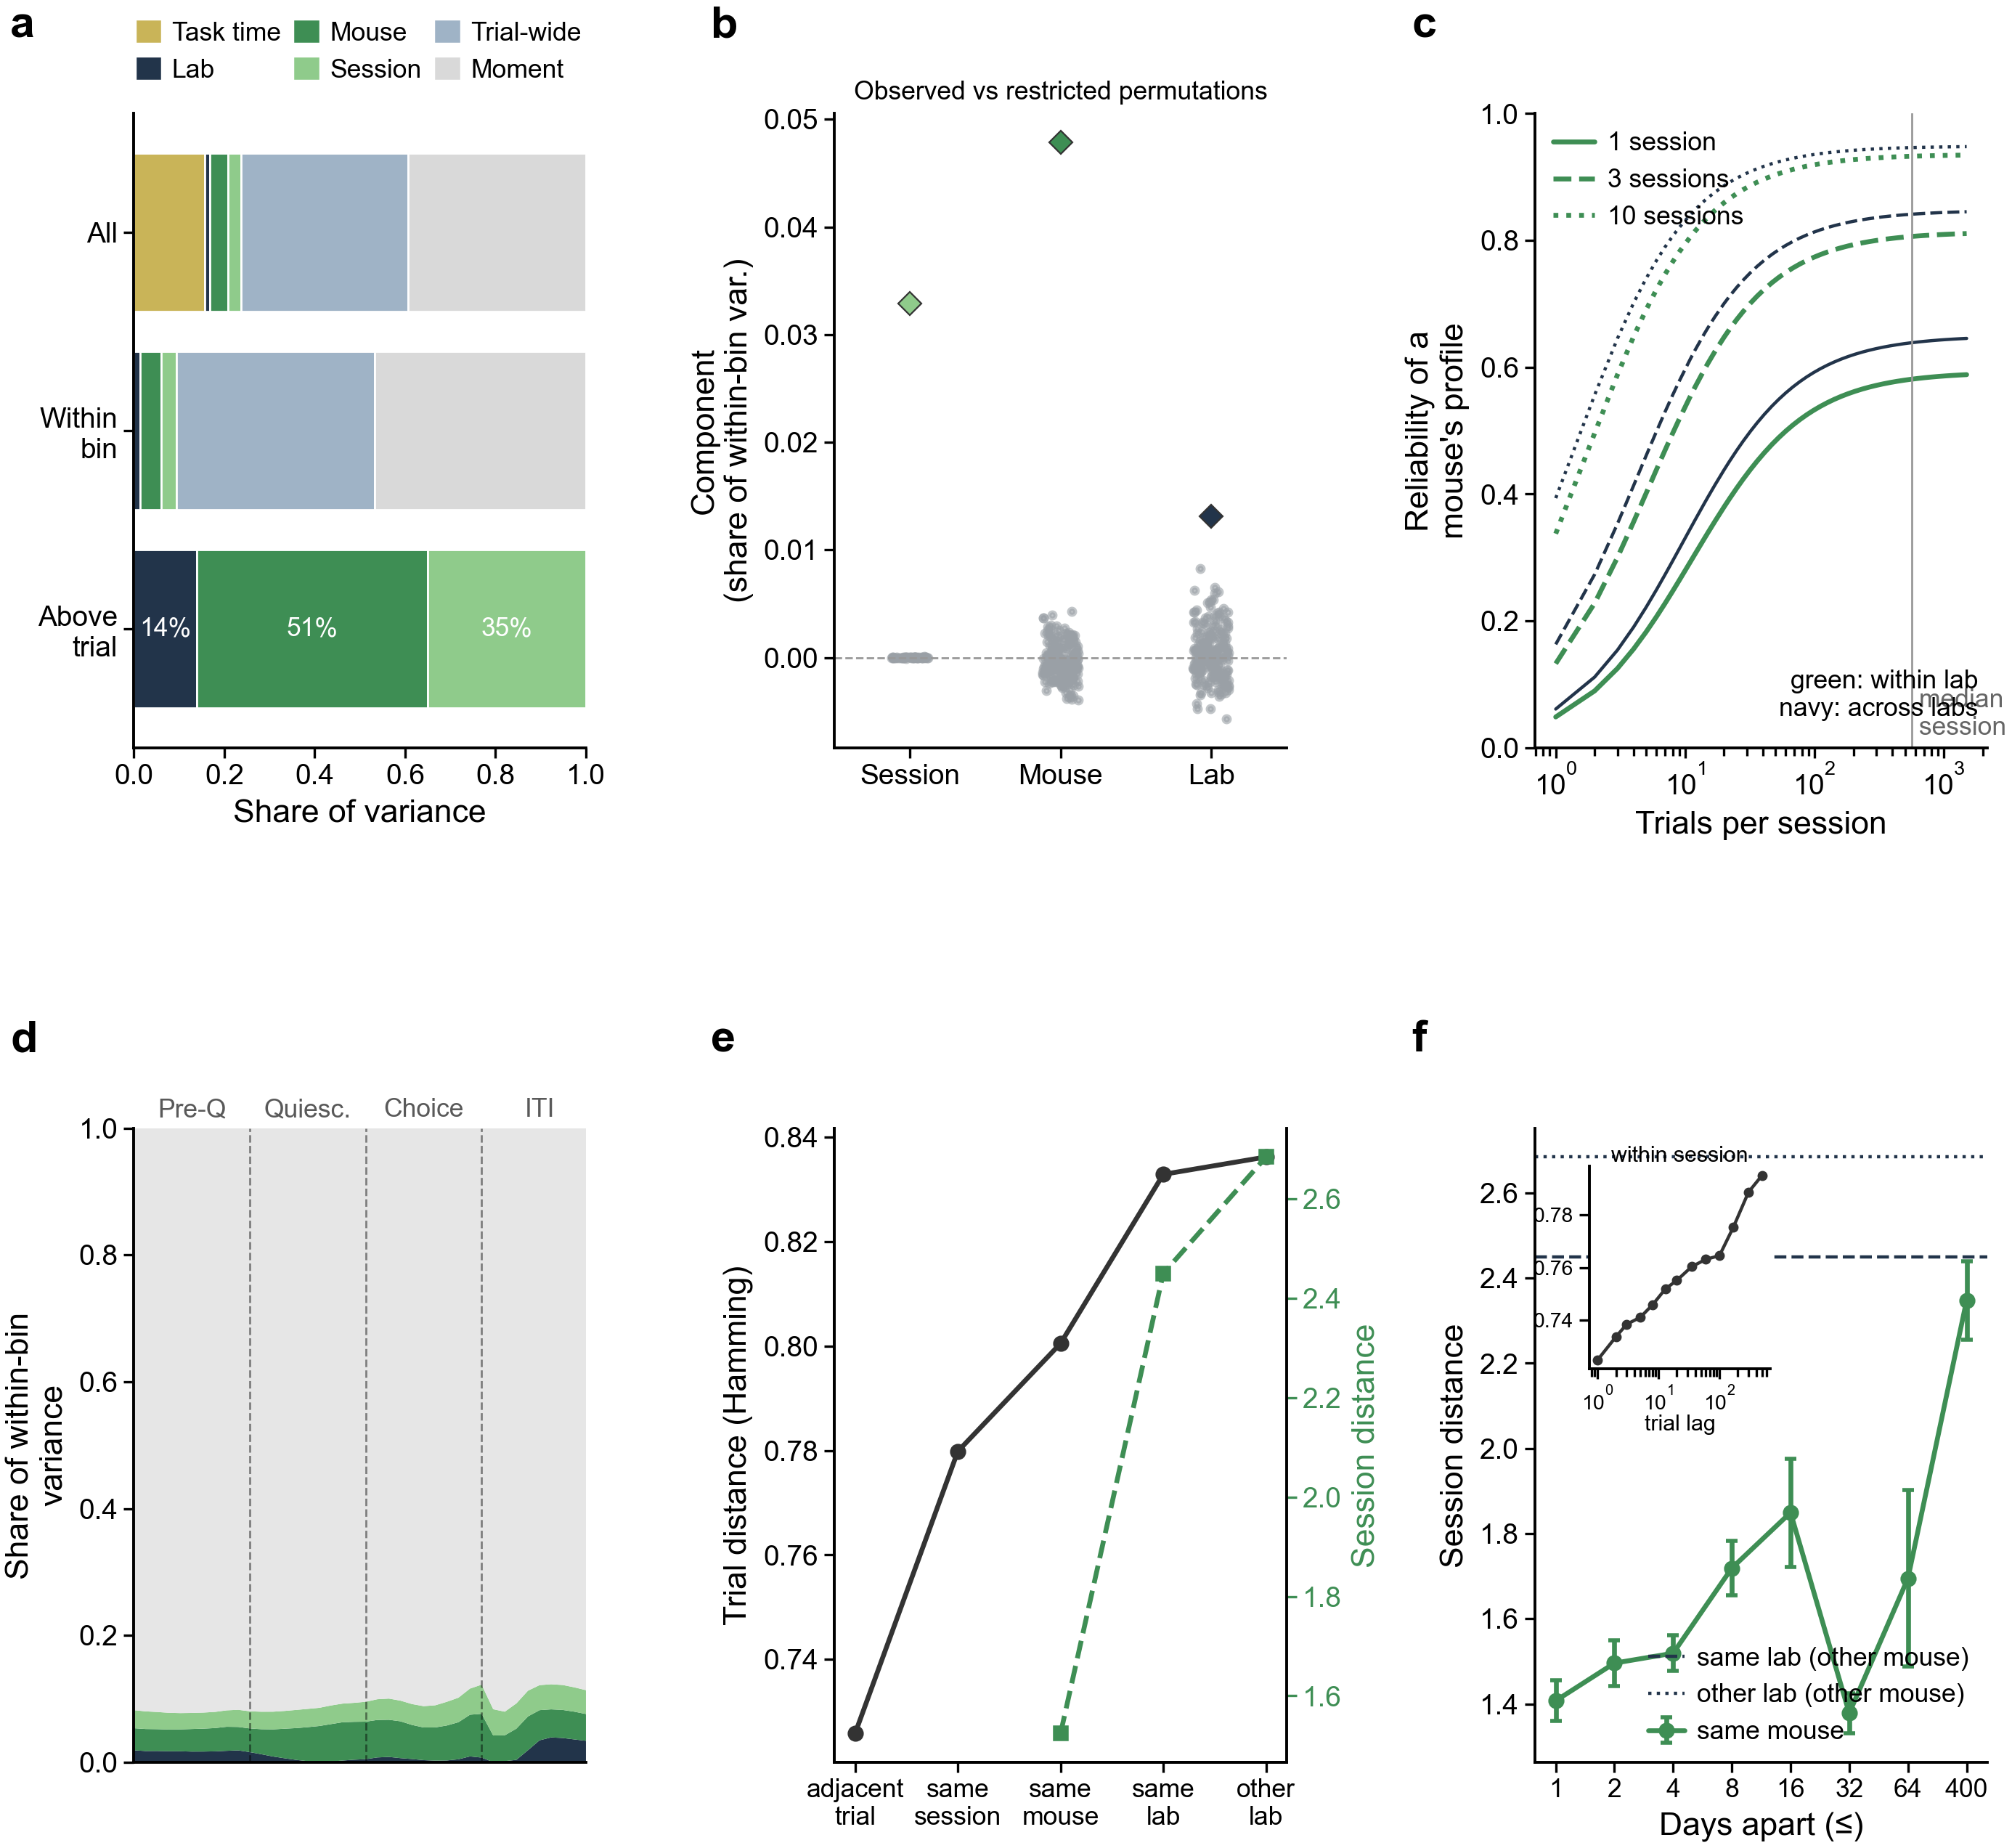

wrote nested_variance/figures/nested_variance_03-11-2026.svg


wrote nested_variance/figures/nested_variance.pdf


wrote nested_variance/figures/nested_variance.png


In [9]:
fig = plt.figure(figsize=(7.09, 6.6))
G = fig.add_gridspec(2, 3, hspace=0.6, wspace=0.55, left=0.08, right=0.98, top=0.94, bottom=0.08)

# a: the variance budget
ax = fig.add_subplot(G[0, 0])
left = 0
for name, val in PARTS.items():
    ax.barh(0, val / PARTS.sum(), left=left, color=LEVEL_COLORS[name], edgecolor='white', lw=0.5)
    left += val / PARTS.sum()
wb = PARTS.drop('Task time'); left = 0
for name, val in wb.items():
    ax.barh(1, val / wb.sum(), left=left, color=LEVEL_COLORS[name], edgecolor='white', lw=0.5)
    left += val / wb.sum()
ab = PARTS[['Lab', 'Mouse', 'Session']]; left = 0
for name, val in ab.items():
    ax.barh(2, val / ab.sum(), left=left, color=LEVEL_COLORS[name], edgecolor='white', lw=0.5)
    if val / ab.sum() > 0.08:
        ax.text(left + val / ab.sum() / 2, 2, f'{100 * val / ab.sum():.0f}%', ha='center', va='center',
                color='white', fontsize=fs_small)
    left += val / ab.sum()
ax.set_yticks([0, 1, 2], ['All', 'Within\nbin', 'Above\ntrial'])
ax.set_ylim(2.6, -0.6)
ax.set_xlim(0, 1); ax.set_xlabel('Share of variance')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in LEVEL_COLORS.values()],
          labels=list(LEVEL_COLORS), frameon=False, fontsize=fs_small, ncol=3, loc='lower center',
          bbox_to_anchor=(0.5, 1.02), handlelength=0.8, columnspacing=0.6)

# b: permutation nulls
ax = fig.add_subplot(G[0, 1])
for x, lvl in enumerate(['session', 'mouse', 'lab']):
    nl = NULL[lvl] / obs.sum()
    ax.plot(x + np.random.default_rng(x).uniform(-0.12, 0.12, len(nl)), nl, 'o', ms=1.5, color=ps.NULL_BAND, alpha=0.6)
    ax.plot(x, obs[['lab', 'mouse', 'session'].index(lvl)] / obs.sum(), 'D', ms=4,
            color=LEVEL_COLORS[lvl.capitalize()], mec='0.2', mew=0.4)
ax.axhline(0, color='0.6', lw=0.5, ls='--')
ax.set_xticks([0, 1, 2], ['Session', 'Mouse', 'Lab']); ax.set_xlim(-0.5, 2.5)
ax.set_ylabel('Component\n(share of within-bin var.)')
ax.set_title('Observed vs restricted permutations', fontsize=fs_small)

# c: reliability
ax = fig.add_subplot(G[0, 2])
for ns, ls in ((1, '-'), (3, '--'), (10, ':')):
    ax.plot(NT, reliability(NT, ns), color=LEVEL_COLORS['Mouse'], ls=ls, label=f'{ns} session' + ('s' if ns > 1 else ''))
    ax.plot(NT, reliability(NT, ns, True), color=LEVEL_COLORS['Lab'], ls=ls, lw=0.8)
ax.axvline(med_nt, color='0.6', lw=0.5); ax.text(med_nt, 0.02, ' median\n session', fontsize=fs_small, color='0.4')
ax.set_xscale('log'); ax.set_ylim(0, 1)
ax.set_xlabel('Trials per session'); ax.set_ylabel('Reliability of a\nmouse\'s profile')
ax.legend(frameon=False, fontsize=fs_small, loc='upper left', handlelength=1.6)
ax.text(0.98, 0.05, 'green: within lab\nnavy: across labs', transform=ax.transAxes, ha='right', fontsize=fs_small)

# d: shares by bin
ax = fig.add_subplot(G[1, 0])
ax.stackplot(np.arange(B), SHARE_BIN, colors=[LEVEL_COLORS[k] for k in ('Lab', 'Mouse', 'Session')] + ['#E6E6E6'])
ps.epoch_lines(ax, B, label=True, names=ps.EPOCH_SHORT)
ax.set_xlim(0, B - 1); ax.set_ylim(0, 1); ax.set_xticks([])
ax.set_ylabel('Share of within-bin\nvariance')

# e: staircase
ax = fig.add_subplot(G[1, 1])
ax2 = ax.twinx()
kt = list(DIST_T)
ax.plot(range(len(kt)), [DIST_T[k].mean() for k in kt], 'o-', color='0.2', ms=3, label='Trials (Hamming)')
ks = list(DIST_S)
ax2.plot(range(2, 2 + len(ks)), [DIST_S[k].mean() for k in ks], 's--', color=LEVEL_COLORS['Mouse'], ms=3)
ax.set_xticks(range(len(kt)), [k.replace(' ', '\n') for k in kt], fontsize=fs_small)
ax.set_ylabel('Trial distance (Hamming)'); ax2.set_ylabel('Session distance', color=LEVEL_COLORS['Mouse'])
ax2.tick_params(axis='y', colors=LEVEL_COLORS['Mouse']); ax2.spines['right'].set_visible(True)

# f: time
ax = fig.add_subplot(G[1, 2])
x = np.arange(len(DAY_SUM))
ax.errorbar(x, DAY_SUM['mean'], yerr=DAY_SUM['sem'], fmt='o-', color=LEVEL_COLORS['Mouse'], ms=3, label='same mouse')
for k, ls in (('same lab', '--'), ('other lab', ':')):
    ax.axhline(DIST_S[k].mean(), color=LEVEL_COLORS['Lab'], ls=ls, lw=0.8, label=k + ' (other mouse)')
ax.set_xticks(x, [f'{int(b.right)}' for b in DAY_SUM.index], fontsize=fs_small)
ax.set_xlabel('Days apart (≤)'); ax.set_ylabel('Session distance')
ax.legend(frameon=False, fontsize=fs_small, loc='lower right')
ins = ax.inset_axes([0.12, 0.62, 0.4, 0.32])
ins.plot(LAGS, LAG_D, 'o-', ms=1.5, color='0.2', lw=0.8); ins.set_xscale('log')
ins.set_xlabel('trial lag', fontsize=fs_small * 0.85, labelpad=0); ins.tick_params(labelsize=fs_small * 0.8)
ins.set_title('within session', fontsize=fs_small * 0.85, pad=1)

MAIN = [a_ for a_ in fig.axes if a_.get_subplotspec() is not None and not any(a_ is t for t in [ax2])]
for a_, letter in zip(MAIN, 'abcdef'):
    b_ = a_.get_position()
    fig.text(b_.x0 - 0.06, b_.y1 + 0.04, letter, fontsize=plt.rcParams['font.size'] + 3, fontweight='bold')
plt.show()
FIGDIR.mkdir(exist_ok=True)
for path in [FIGDIR / f"nested_variance_{date.today().strftime('%d-%m-%Y')}.svg", FIGDIR / 'nested_variance.pdf',
             FIGDIR / 'nested_variance.png']:
    fig.savefig(path, dpi=300)
    print('wrote', path.relative_to(PI))